**Problem statement:**

This project aims to build a time series forecasting model that can predict the number of page views for future dates for an Ads marketing company. We are provided with a dataset of 145k wikipedia pages and daily view count for each of them for 550 days and our aim is to predict the daily views for future dates. There is one more file containing the presence or absence of an external event that could affect the page views. We will use popular time series forecasting techniques like ARIMA, SARIMAX and Prophet and use grid search techniques to achieve the lowest MAPE.

**There are two csv files given:**

**train_1.csv**: In the csv file, each row corresponds to a particular article and each column corresponds to a particular date. The values are the number of visits on that date.

The page name contains data in this format:

SPECIFIC NAME _ LANGUAGE.wikipedia.org _ ACCESS TYPE _ ACCESS ORIGIN

having information about the page name, the main domain, the device type used to access the page, and also the request origin(spider or browser agent)


**Exog_Campaign_eng**: This file contains data for the dates which had a campaign or significant event that could affect the views for that day. The data is just for pages in English.

There’s 1 for dates with campaigns and 0 for remaining dates.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

In [ ]:
train = pd.read_csv('/content/train_1.csv')
exog = pd.read_csv('/content/Exog_Campaign_eng.csv')

print("Train shape:", train.shape)
print("Exogenous shape:", exog.shape)

Train shape: (145063, 551)
Exogenous shape: (550, 1)


In [ ]:
train.head()

,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-22,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,32.0,63.0,15.0,26.0,14.0,20.0,22.0,19.0,18.0,20.0
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,17.0,42.0,28.0,15.0,9.0,30.0,52.0,45.0,26.0,20.0
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,3.0,1.0,1.0,7.0,4.0,4.0,6.0,3.0,4.0,17.0
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,32.0,10.0,26.0,27.0,16.0,11.0,17.0,19.0,10.0,11.0
4,52_Hz_I_Love_You_zh.wikipedia.org_all-access_s...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,48.0,9.0,25.0,13.0,3.0,11.0,27.0,13.0,36.0,10.0


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145063 entries, 0 to 145062
Columns: 551 entries, Page to 2016-12-31
dtypes: float64(550), object(1)
memory usage: 609.8+ MB


In [ ]:
print(train.isna().sum())

Page              0
2015-07-01    20740
2015-07-02    20816
2015-07-03    20544
2015-07-04    20654
              ...  
2016-12-27     3701
2016-12-28     3822
2016-12-29     3826
2016-12-30     3635
2016-12-31     3465
Length: 551, dtype: int64


In [ ]:
exog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Exog    550 non-null    int64
dtypes: int64(1)
memory usage: 4.4 KB


In [ ]:
# Calculate the percentage of missing values for each row
missing_percentage_row = (train.isna().sum(axis=1) / train.shape[1]) * 100

# Identify rows where more than 40% of values are NaN
rows_to_drop_mask = missing_percentage_row > 40

# Drop the identified rows from the DataFrame in-place
original_rows = len(train)
train.drop(index=train.index[rows_to_drop_mask], inplace=True)
rows_after_dropping = len(train)


print(f"Original number of rows: {original_rows}")
print(f"Number of rows after dropping rows with > 40% NaNs: {rows_after_dropping}")

# Display the first few rows of the modified DataFrame
display(train.head())

Original number of rows: 145063
Number of rows after dropping rows with > 40% NaNs: 132299


,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-22,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,32.0,63.0,15.0,26.0,14.0,20.0,22.0,19.0,18.0,20.0
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,17.0,42.0,28.0,15.0,9.0,30.0,52.0,45.0,26.0,20.0
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,3.0,1.0,1.0,7.0,4.0,4.0,6.0,3.0,4.0,17.0
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,32.0,10.0,26.0,27.0,16.0,11.0,17.0,19.0,10.0,11.0
5,5566_zh.wikipedia.org_all-access_spider,12.0,7.0,4.0,5.0,20.0,8.0,5.0,17.0,24.0,...,16.0,27.0,8.0,17.0,32.0,19.0,23.0,17.0,17.0,50.0


In [ ]:
# Extracting language from 'Page' column and add it to the DataFrame
train['language'] = train['Page'].apply(lambda x: x.split('.wikipedia.org')[0].split('_')[-1])

# Selecting only the numeric columns (dates) for imputation
date_cols = train.columns.drop(['Page', 'language'])

# Imputing missing values using linear interpolation (centered average)
train[date_cols] = train[date_cols].interpolate(method='linear', axis=1, limit_direction="both", limit_area=None)

# Check for remaining NaNs after linear interpolation
print("Number of remaining NaNs after linear interpolation:")
print(train[date_cols].isna().sum().sum())

# Display the first few rows of the modified train DataFrame
display(train.head())

Number of remaining NaNs after linear interpolation:
0


,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31,language
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,63.0,15.0,26.0,14.0,20.0,22.0,19.0,18.0,20.0,zh
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,42.0,28.0,15.0,9.0,30.0,52.0,45.0,26.0,20.0,zh
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,1.0,1.0,7.0,4.0,4.0,6.0,3.0,4.0,17.0,zh
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,10.0,26.0,27.0,16.0,11.0,17.0,19.0,10.0,11.0,zh
5,5566_zh.wikipedia.org_all-access_spider,12.0,7.0,4.0,5.0,20.0,8.0,5.0,17.0,24.0,...,27.0,8.0,17.0,32.0,19.0,23.0,17.0,17.0,50.0,zh


**Observations:**

1) Train_1 dataset has 551 columns where the first column is the page details and the remaining 550 columns are the datewise number of page visits
2) Exogenous dataset contains a flag representing the presence of an external event for all 550 days which can be used as an exogenous variable
3) Train_1 has 145063 records and 551 columns whereas the first column is an object datatype and the remaining are float datatype. Similarly the exog dataset has datatype as integer with binary values of 0 and 1.
4) There are many NaNs in the Train_1 dataset and we drop those rows where NaNs are present in more than 40% of the columns for that row. After doing this we are left with 1.32k rows from the original 1.45k rows.
5) For those rows which still have NaNs, we perform linear interpolation (centered average logic) to impute the missing values. After doing this we can observe that our dataframe no longer contains NaN values.

In [ ]:
# Extracting page name, language, device type, and access origin
def extract_page_info(page_string):
    parts = page_string.split('.wikipedia.org')
    page_part = parts[0]
    domain_part = parts[1] if len(parts) > 1 else ''

    # Splitting the page part to get potential language and page name
    page_parts_split = page_part.split('_')

    # Initializing language and page_name
    language = None
    # Assuming the whole part before .wikipedia.org is the page name initially
    page_name = page_part

    # Attempting to extract language more carefully
    if len(page_parts_split) > 1:
        potential_language = page_parts_split[-1]
        # Define a list of expected language codes (can be expanded)
        known_languages = ['zh', 'fr', 'en', 'ru', 'de', 'ja', 'es', 'commons'] # Added 'commons' as a special case if needed, but we aim to exclude it from language
        # Check if the last part looks like a language code or is in our known list
        if (len(potential_language) <= 3 and potential_language.isalpha()) or potential_language in known_languages:
             language = potential_language
             page_name = '_'.join(page_parts_split[:-1])
        # If it doesn't look like a language, assume the whole thing before .wikipedia.org is the page name
        # language remains None


    # Splitting the domain part to get access and agent
    domain_parts_split = domain_part.split('_')
    # Filtering out empty strings that might result from multiple underscores
    domain_parts_split = [part for part in domain_parts_split if part]

    access = None
    agent = None

    # Determining access and agent based on the remaining parts
    if len(domain_parts_split) >= 2:
        # Assuming the last two parts are access and agent
        access = domain_parts_split[-2]
        agent = domain_parts_split[-1]
    elif len(domain_parts_split) == 1:
        # If only one part remains, it's likely the agent if it's a known type
        if domain_parts_split[0] in ['spider', 'all-agents']:
             agent = domain_parts_split[0]

    return page_name, language, access, agent

# Applying the function to the 'Page' column and create new columns

if 'Page' in train.columns:
    train[['page_name', 'language', 'access', 'agent']] = train['Page'].apply(lambda x: pd.Series(extract_page_info(x)))

    # Dropping the original 'Page' column as we have extracted the required information
    train = train.drop(columns=['Page'])

    # Displaying the first few rows with the new columns
    display(train.head())
else:
    print("The 'Page' column does not exist in the DataFrame. Please ensure the correct DataFrame is being used.")

,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,2015-07-10,...,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31,language,page_name,access,agent
0,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,24.0,...,14.0,20.0,22.0,19.0,18.0,20.0,zh,2NE1,all-access,spider
1,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,4.0,...,9.0,30.0,52.0,45.0,26.0,20.0,zh,2PM,all-access,spider
2,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,4.0,...,4.0,4.0,6.0,3.0,4.0,17.0,zh,3C,all-access,spider
3,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,16.0,...,16.0,11.0,17.0,19.0,10.0,11.0,zh,4minute,all-access,spider
5,12.0,7.0,4.0,5.0,20.0,8.0,5.0,17.0,24.0,7.0,...,32.0,19.0,23.0,17.0,17.0,50.0,zh,5566,all-access,spider


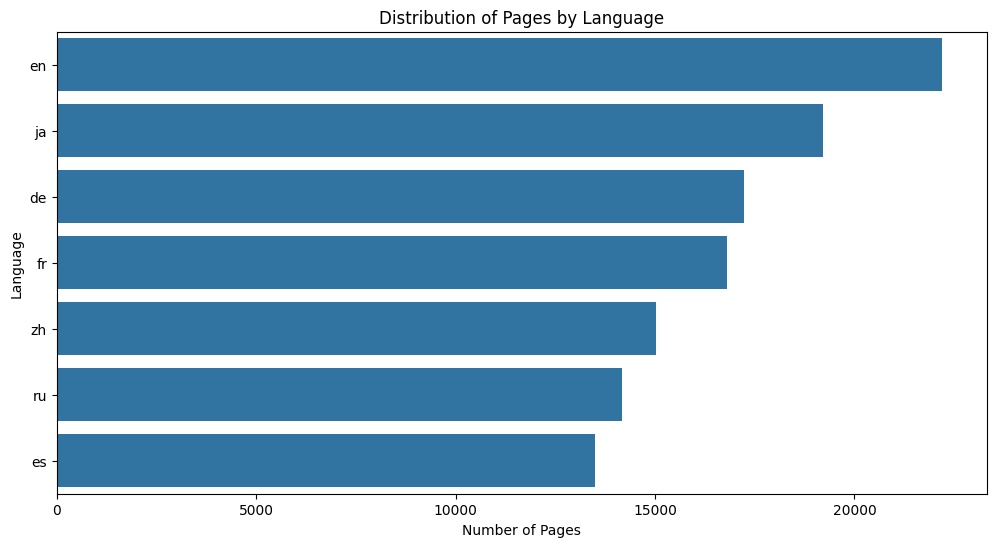

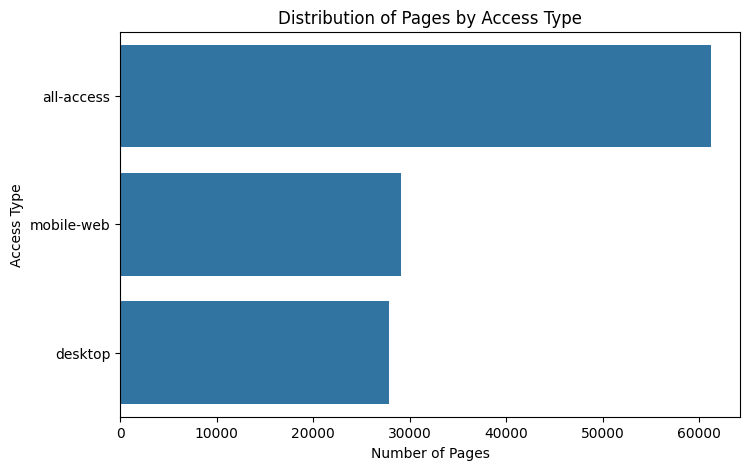

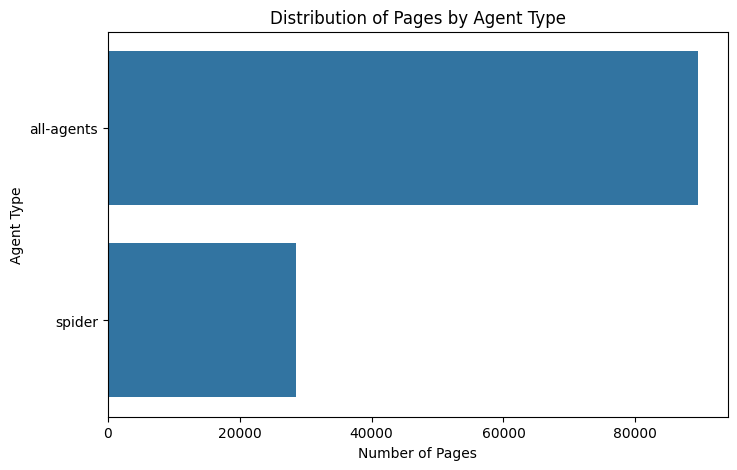

In [ ]:
# Plot countplot for 'language'
plt.figure(figsize=(12, 6))
sns.countplot(data=train, y='language', order=train['language'].value_counts().index)
plt.title('Distribution of Pages by Language')
plt.xlabel('Number of Pages')
plt.ylabel('Language')
plt.show()

# Plot countplot for 'access'
plt.figure(figsize=(8, 5))
sns.countplot(data=train, y='access', order=train['access'].value_counts().index)
plt.title('Distribution of Pages by Access Type')
plt.xlabel('Number of Pages')
plt.ylabel('Access Type')
plt.show()

# Plot countplot for 'agent'
plt.figure(figsize=(8, 5))
sns.countplot(data=train, y='agent', order=train['agent'].value_counts().index)
plt.title('Distribution of Pages by Agent Type')
plt.xlabel('Number of Pages')
plt.ylabel('Agent Type')
plt.show()

In [ ]:
train.groupby('language').count()

,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,2015-07-10,...,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31,page_name,access,agent
language,,,,,,,,,,,,,,,,,,,,,
de,17236,17236,17236,17236,17236,17236,17236,17236,17236,17236,...,17236,17236,17236,17236,17236,17236,17236,17236,17236,17236
en,22204,22204,22204,22204,22204,22204,22204,22204,22204,22204,...,22204,22204,22204,22204,22204,22204,22204,22204,22204,22204
es,13492,13492,13492,13492,13492,13492,13492,13492,13492,13492,...,13492,13492,13492,13492,13492,13492,13492,13492,13492,13492
fr,16814,16814,16814,16814,16814,16814,16814,16814,16814,16814,...,16814,16814,16814,16814,16814,16814,16814,16814,16814,16814
ja,19214,19214,19214,19214,19214,19214,19214,19214,19214,19214,...,19214,19214,19214,19214,19214,19214,19214,19214,19214,19214
ru,14179,14179,14179,14179,14179,14179,14179,14179,14179,14179,...,14179,14179,14179,14179,14179,14179,14179,14179,14179,14179
zh,15016,15016,15016,15016,15016,15016,15016,15016,15016,15016,...,15016,15016,15016,15016,15016,15016,15016,15016,15016,15016


In [ ]:
train_new = train.groupby('language').mean(numeric_only=True).transpose()
train_new.head()

language,de,en,es,fr,ja,ru,zh
2015-07-01,778.959445,3872.589533,1139.622517,520.894493,624.426564,695.691586,296.163958
2015-07-02,768.487364,3860.240102,1089.418836,524.125306,715.963174,707.242739,296.565214
2015-07-03,737.972329,3667.878653,1002.454196,504.658846,647.313998,657.577351,294.692831
2015-07-04,678.000178,3816.300258,941.511668,538.080925,811.440136,620.183175,297.338990
2015-07-05,786.607363,3939.499119,1023.311742,528.606955,778.742326,658.371867,315.836608


**Preprocessing and EDA:**

1) We now extract the page name, language, access type and access origin from the page title column using split function and put these into separate columns in the dataframe 'train'.
2) Since language, access type and acess origin are categorical variables we use countplot to plot the distribution.
3) We can see that 'en' ie English has the highest page count out of all the languages followed by 'ja' (japanase) and 'de' (german). There is no single language having considerably higher count compared to other languages.
4) 'acc-access' type has almost twice the number of pages compared to mobile-web or desktop which have almost similar count.
5) Similarly all-agents has 3 to 4 times more page count compared to spider.
6) We now convert the data from wide format to long format to make the dataset appropriate to perform forecasting.

Text(0, 0.5, 'Average page view for each language')

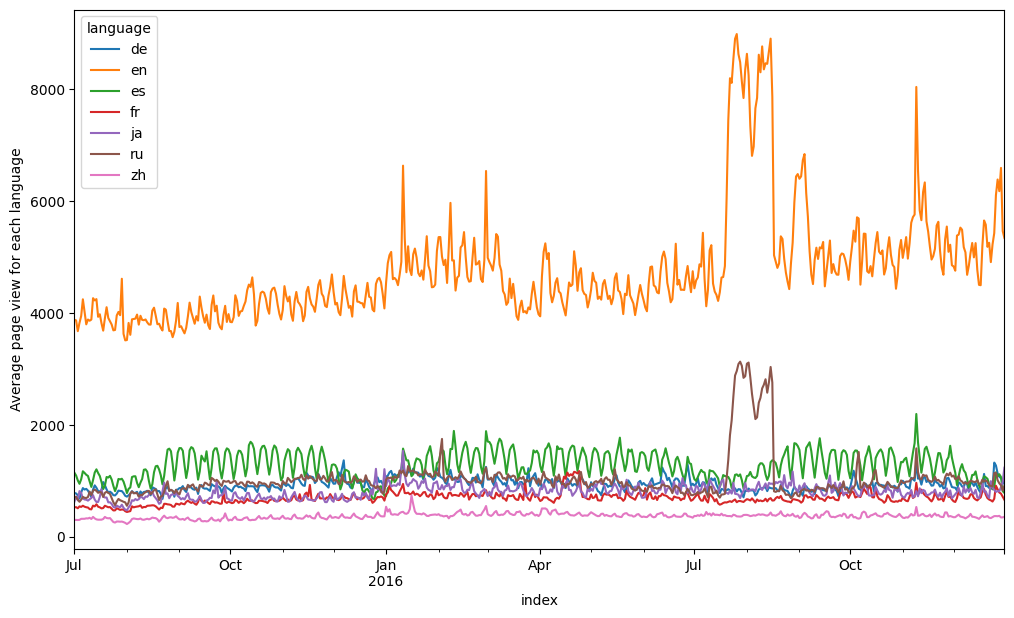

In [ ]:
train_new.reset_index(inplace=True)
# Converting the 'index' column to datetime objects before setting it as the index
train_new['index'] = pd.to_datetime(train_new['index'])
train_new.set_index('index', inplace=True)

train_new.plot(figsize=(12,7))
plt.ylabel('Average page view for each language')

In [ ]:
# Extracting the time series for the 'en' language from train_new
train_en = train_new['en']

# Performing the Augmented Dickey-Fuller test on the English language time series
adf_result_en = adfuller(train_en)

# Printing the results
print('\nADF Statistic for English Language (train_new): %f' % adf_result_en[0])
print('p-value: %f' % adf_result_en[1])
print('Critical Values:')
for key, value in adf_result_en[4].items():
    print('\t%s: %.3f' % (key, value))

# Interpreting the result
if adf_result_en[1] <= 0.05:
    print("\nResult: The English language time series (train_new) is likely stationary (reject the null hypothesis).")
else:
    print("\nResult: The English language time series (train_new) is likely non-stationary (fail to reject the null hypothesis).")


ADF Statistic for English Language (train_new): -2.418375
p-value: 0.136617
Critical Values:
	1%: -3.443
	5%: -2.867
	10%: -2.570

Result: The English language time series (train_new) is likely non-stationary (fail to reject the null hypothesis).


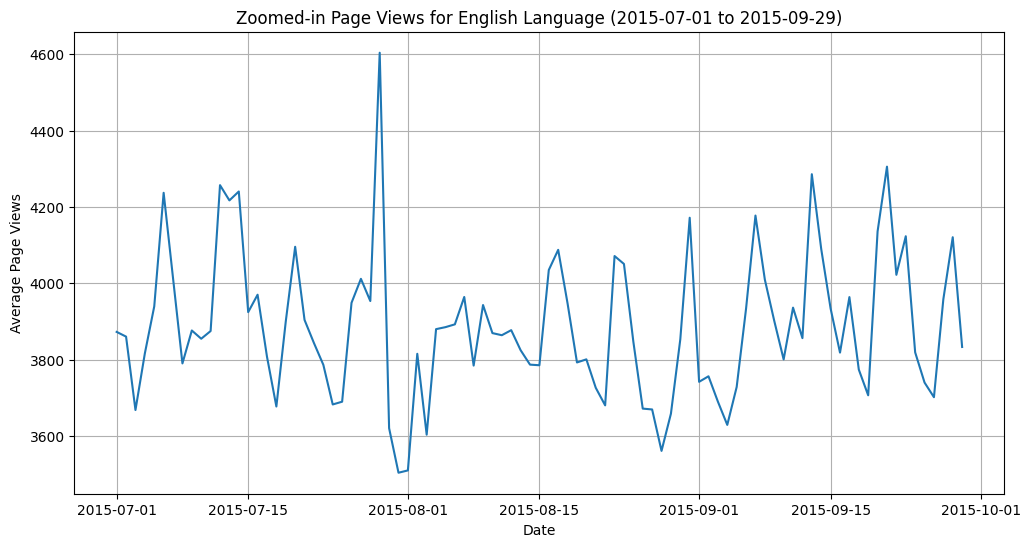

In [ ]:
# Selecting the time series for the 'en' language from train_new
english_language_ts = train_new['en']

# Defining a smaller time period to zoom in (e.g., the first 3 months)
# Ensuring the start and end dates are within the range of your data
start_date = english_language_ts.index[0]
end_date = english_language_ts.index[0] + pd.Timedelta(days=90) # Example: first 90 days

# Slicing the time series for the selected period
zoomed_ts = english_language_ts.loc[start_date:end_date]

# Plot the zoomed time series
plt.figure(figsize=(12, 6))
plt.plot(zoomed_ts.index, zoomed_ts)
plt.title(f'Zoomed-in Page Views for English Language ({start_date.date()} to {end_date.date()})')
plt.xlabel('Date')
plt.ylabel('Average Page Views')
plt.grid(True)
plt.show()

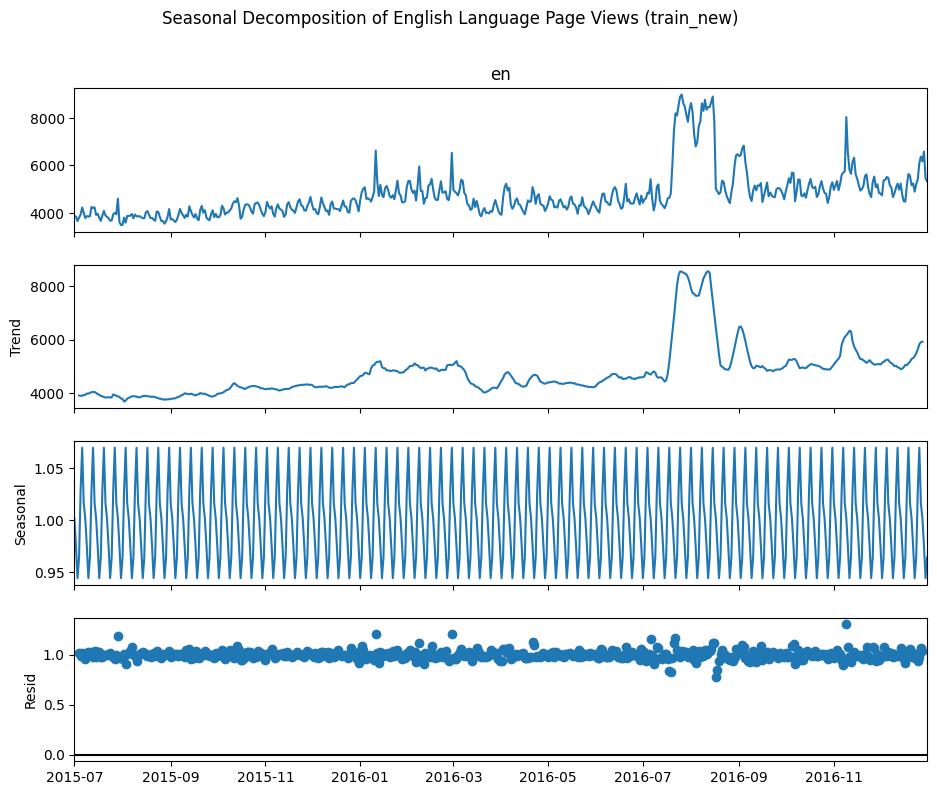

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Perform seasonal decomposition on the English language time series (train_en)
decomposition = seasonal_decompose(train_en, model='multiplicative', period=7)

# Plot the decomposed components
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.suptitle('Seasonal Decomposition of English Language Page Views (train_new)', y=1.02)
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller
import numpy as np

# Extracting the residual component from the decomposition object
residuals = decomposition.resid

residuals_cleaned = residuals.dropna()

# Performing the Augmented Dickey-Fuller test on the residuals
if len(residuals_cleaned) > 0:
    adf_result_residuals = adfuller(residuals_cleaned)

    # Printing the results
    print('\nADF Statistic for Residuals: %f' % adf_result_residuals[0])
    print('p-value: %f' % adf_result_residuals[1])
    print('Critical Values:')
    for key, value in adf_result_residuals[4].items():
        print('\t%s: %.3f' % (key, value))

    # Interpreting the result
    if adf_result_residuals[1] <= 0.05:
        print("\nResult: The residuals are likely stationary (reject the null hypothesis).")
    else:
        print("\nResult: The residuals are likely non-stationary (fail to reject the null hypothesis).")
else:
    print("Residuals time series is empty after dropping NaNs, cannot perform ADF test.")


ADF Statistic for Residuals: -10.227903
p-value: 0.000000
Critical Values:
	1%: -3.443
	5%: -2.867
	10%: -2.570

Result: The residuals are likely stationary (reject the null hypothesis).


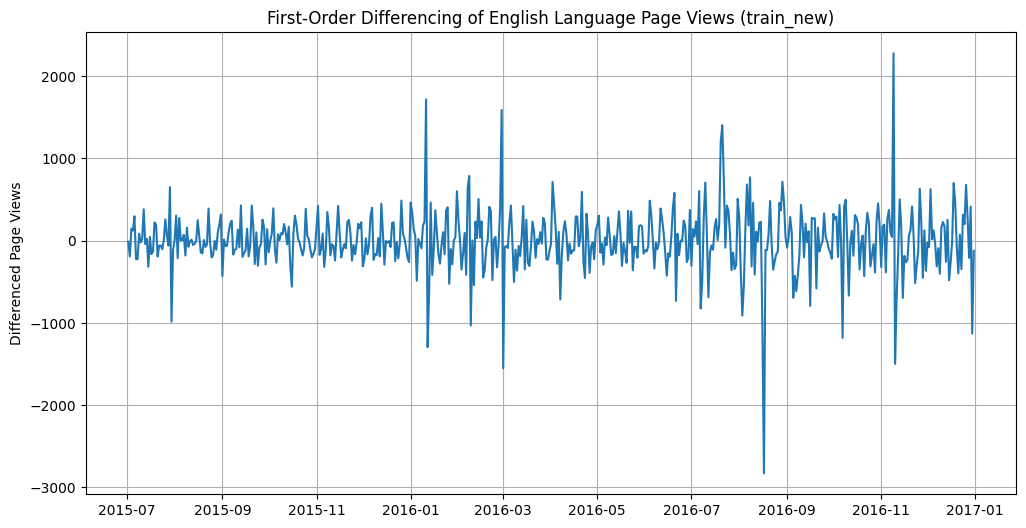

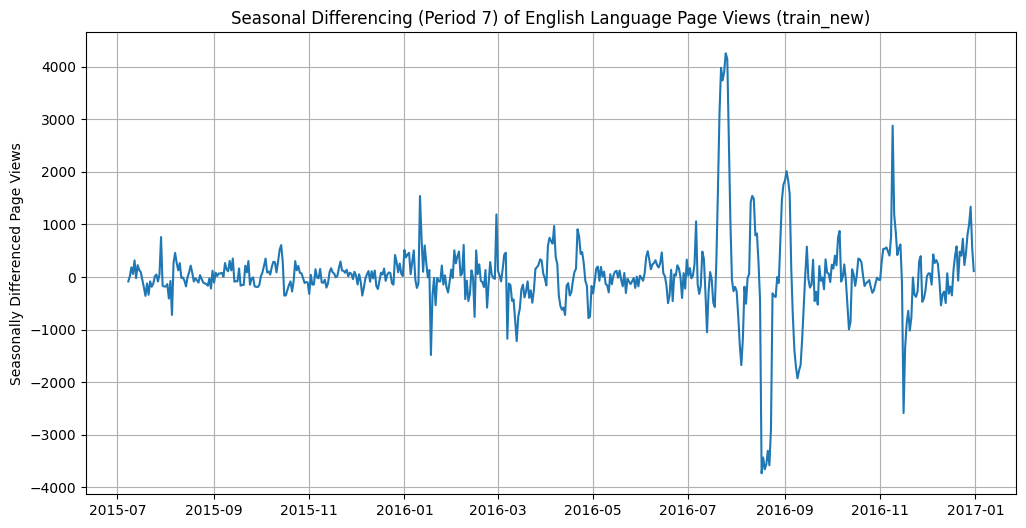

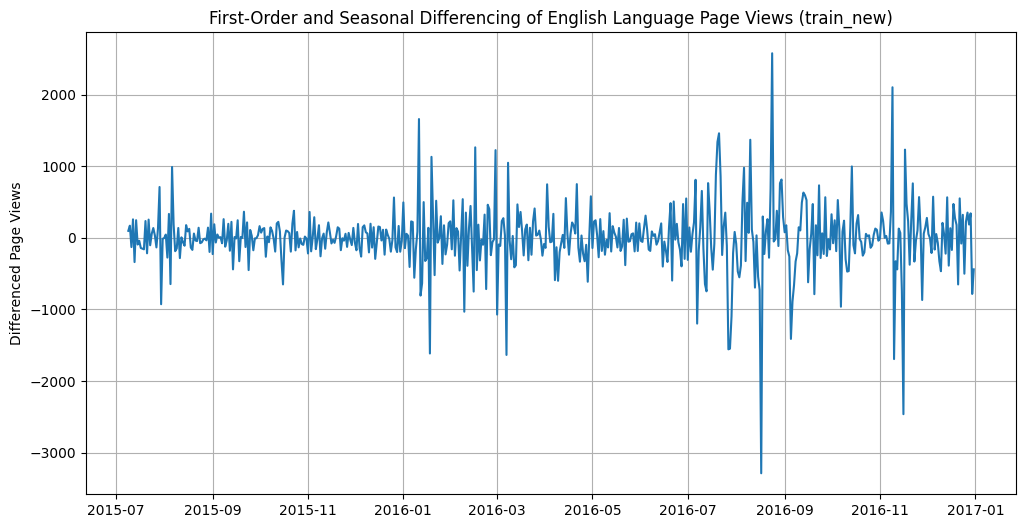

In [ ]:
# Removing trend using first-order differencing
train_en_diff = train_en.diff().dropna()

# Plot the differenced series
plt.figure(figsize=(12, 6))
plt.plot(train_en_diff)
plt.title('First-Order Differencing of English Language Page Views (train_new)')
plt.ylabel('Differenced Page Views')
plt.grid(True)
plt.show()

# Removing seasonality using seasonal differencing (period=7 for weekly seasonality)
train_en_seasonal_diff = train_en.diff(periods=7).dropna()

# Plot the seasonally differenced series
plt.figure(figsize=(12, 6))
plt.plot(train_en_seasonal_diff)
plt.title('Seasonal Differencing (Period 7) of English Language Page Views (train_new)')
plt.ylabel('Seasonally Differenced Page Views')
plt.grid(True)
plt.show()


train_en_diff_seasonal_diff = train_en.diff(periods=7).diff().dropna()

# Plot the series after both differencing steps
plt.figure(figsize=(12, 6))
plt.plot(train_en_diff_seasonal_diff)
plt.title('First-Order and Seasonal Differencing of English Language Page Views (train_new)')
plt.ylabel('Differenced Page Views')
plt.grid(True)
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Performing the Augmented Dickey-Fuller test on the first-order differenced series (train_en_diff)
adf_result_diff = adfuller(train_en_diff)

# Printing the results
print('\nADF Statistic for First-Order Differenced English Language Time Series: %f' % adf_result_diff[0])
print('p-value: %f' % adf_result_diff[1])
print('Critical Values:')
for key, value in adf_result_diff[4].items():
    print('\t%s: %.3f' % (key, value))

# Interpreting the result
if adf_result_diff[1] <= 0.05:
    print("\nResult: The first-order differenced time series is likely stationary (reject the null hypothesis).")
else:
    print("\nResult: The first-order differenced time series is likely non-stationary (fail to reject the null hypothesis).")


ADF Statistic for First-Order Differenced English Language Time Series: -8.269981
p-value: 0.000000
Critical Values:
	1%: -3.443
	5%: -2.867
	10%: -2.570

Result: The first-order differenced time series is likely stationary (reject the null hypothesis).


***Stationary check:***

1) We now plot all the 7 time series plots of each language in a single plot. We can see that 'en' has way higher number of page visits compared to other languages. Also there is an upward trend in case of 'en' whereas there is no/negligible trend in other languages.
2) To perform ARIMA or other forecasting models, we need to check if our time series is stationary. We use adfuller test for 'en' language and can see that the p-value is > 0.05 indicating non-stationarity.
3) We now convert our non-stationary time series to stationary time series through 2 methods: decomposition and differencing
      *   **Decomposition**: We use the seasonal_decompose function to remove the trend and seasonality of the time series and use multiplicative method since from the plot we can see that the amplitude of the series increases over time rather than being constant. Also we can see from the zoomed version of the plot for 'en' language that there is a seasonality of the data every 7 days occuring most of the time. Hence we use period = 7 in our seasonal_decompose function. After doing seasonal decompose we can see that the residuals data is now a stationary series based on adfuller test.
      *   **Differencing**: We now take the first order difference (lag 1) of the series with itself. From the plot we can see that the differenced series has a pretty much constant mean implying that the original series had a trend which is now removed. We also do seasonal_difference with a period of 7 ie. 7 days to remove the seasonality. We can see that the plot now has much less seasonality compared to the original series. We now combine first order difference and seasonal difference to remove both trend and seasonality and we can see from the plot that this new series fluctuates around a mean (0) indicating stationary and the adfuller test also confirms the same.



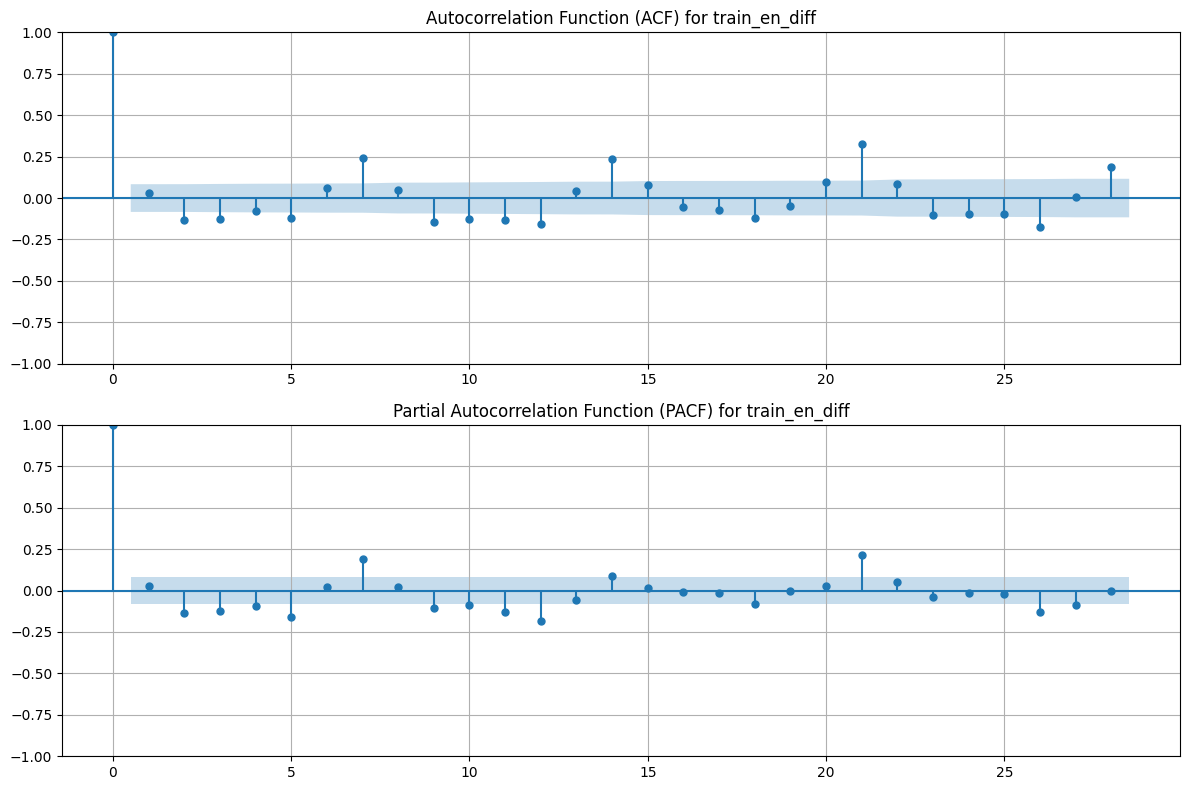

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF and PACF for the first-order differenced English language time series (train_en_diff)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Plot ACF
plot_acf(train_en_diff, ax=axes[0])
axes[0].set_title('Autocorrelation Function (ACF) for train_en_diff')
axes[0].grid(True)

# Plot PACF
plot_pacf(train_en_diff, ax=axes[1])
axes[1].set_title('Partial Autocorrelation Function (PACF) for train_en_diff')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt
import pandas as pd
import itertools
from sklearn.metrics import mean_absolute_percentage_error
import warnings

warnings.filterwarnings("ignore") # Ignore warnings from ARIMA fitting

# Defining the split point (e.g., the last 30 days for testing)
test_size = 30
train_data = train_en[:-test_size]
test_data = train_en[-test_size:]

# Defining the range for p, d, and q
p_range = range(0, 8) # 0 to 7
d_range = [1] # Fixed d at 1
q_range = range(0, 8) # 0 to 7

# Creating a list of all possible combinations of (p, d, q)
pdq_combinations = list(itertools.product(p_range, d_range, q_range))

# Initializing variables to store the best parameters and lowest MAPE
best_order = None
lowest_mape = float('inf') # Initialize with a very high value

print("Performing grid search for ARIMA model...")

for order in pdq_combinations:
    try:
        # Define the ARIMA model
        model_arima = ARIMA(train_data, order=order)


        model_arima_fit = model_arima.fit()


        predictions_arima = model_arima_fit.predict(start=test_data.index[0], end=test_data.index[-1])

        # Ensure actual_values and predictions_arima are aligned by index
        actual_values_aligned, predictions_arima_aligned = test_data.align(predictions_arima, join='inner')

        # Handle zero values in actual_values
        epsilon = 1e-8 # A small number to avoid division by zero
        actual_values_for_mape = actual_values_aligned.replace(0, epsilon)


        mape = mean_absolute_percentage_error(actual_values_for_mape, predictions_arima_aligned)

        # Check if the current MAPE is lower than the lowest found so far
        if mape < lowest_mape:
            lowest_mape = mape
            best_order = order

        print(f"ARIMA{order} - MAPE: {mape:.4f}")

    except Exception as e:

        print(f"ARIMA{order} - Error: {e}")
        continue

print("\nGrid search complete.")
print(f"Order with the lowest MAPE on the test set: {best_order}")
print(f"Lowest MAPE: {lowest_mape:.4f}")

Performing grid search for ARIMA model...
ARIMA(0, 1, 0) - MAPE: 0.0956
ARIMA(0, 1, 1) - MAPE: 0.0956
ARIMA(0, 1, 2) - MAPE: 0.0879
ARIMA(0, 1, 3) - MAPE: 0.0838
ARIMA(0, 1, 4) - MAPE: 0.0831
ARIMA(0, 1, 5) - MAPE: 0.0768
ARIMA(0, 1, 6) - MAPE: 0.0765
ARIMA(0, 1, 7) - MAPE: 0.0788
ARIMA(1, 1, 0) - MAPE: 0.0957
ARIMA(1, 1, 1) - MAPE: 0.0668
ARIMA(1, 1, 2) - MAPE: 0.0745
ARIMA(1, 1, 3) - MAPE: 0.0664
ARIMA(1, 1, 4) - MAPE: 0.0684
ARIMA(1, 1, 5) - MAPE: 0.0767
ARIMA(1, 1, 6) - MAPE: 0.0779
ARIMA(1, 1, 7) - MAPE: 0.0788
ARIMA(2, 1, 0) - MAPE: 0.0901
ARIMA(2, 1, 1) - MAPE: 0.0774
ARIMA(2, 1, 2) - MAPE: 0.0738
ARIMA(2, 1, 3) - MAPE: 0.0682
ARIMA(2, 1, 4) - MAPE: 0.0675
ARIMA(2, 1, 5) - MAPE: 0.0756
ARIMA(2, 1, 6) - MAPE: 0.0700
ARIMA(2, 1, 7) - MAPE: 0.0677
ARIMA(3, 1, 0) - MAPE: 0.0881
ARIMA(3, 1, 1) - MAPE: 0.0664
ARIMA(3, 1, 2) - MAPE: 0.0774
ARIMA(3, 1, 3) - MAPE: 0.0659
ARIMA(3, 1, 4) - MAPE: 0.0677
ARIMA(3, 1, 5) - MAPE: 0.0715
ARIMA(3, 1, 6) - MAPE: 0.0676
ARIMA(3, 1, 7) - MAPE: 0.070

**Forecasting using ARIMA:**

1) We now plot the ACF and PACF plots to identify the autocorrelation of the time series data as well as to arrive at the order parameters (p,d,q) for the ARIMA model.
2) From the ACF and PACF plots, we can see a high correlation after 7 time period and hence we can say the seasonality of the data is 7.
3) We now prepare the data for ARIMA forecasting and split the data into train and test where the last 30 days data is our test data. To identify the parameters (p,d,q), we use the following approach:
      *   For 'p':   Since the correlation values spike at multiples of 7 days ie. lag 7, lag 14 etc. we can consider p=1 or 2 but here we explore till 7 so that we get an optimal value for p.
      *   For 'd':   We use 1 for this as the ADF test for the first order differenced data showed that the series became stationary after differencing.
      *   For 'q':   While the correlation values spiked at lag 7 but not so much at lag 14 etc. we can consider p=1 but here we explore till 7 so that we get an optimal value for q.
4) We now run the ARIMA model for all possible combinations of (p,d,q) and identify the best parameters based on lowest MAPE. The results show that (6,1,6) is the ideal choice for order paramters for this data and the MAPE for this model is 6.3%.
5) There is still some scope to reduce this MAPE further since we have not considered the effect of the exogenous variable which we will now consider using the SARIMAX model.

Building SARIMAX model with non-seasonal order (6, 1, 6) and seasonal order (0, 0, 0, 7)...
Fitting SARIMAX model on training data...


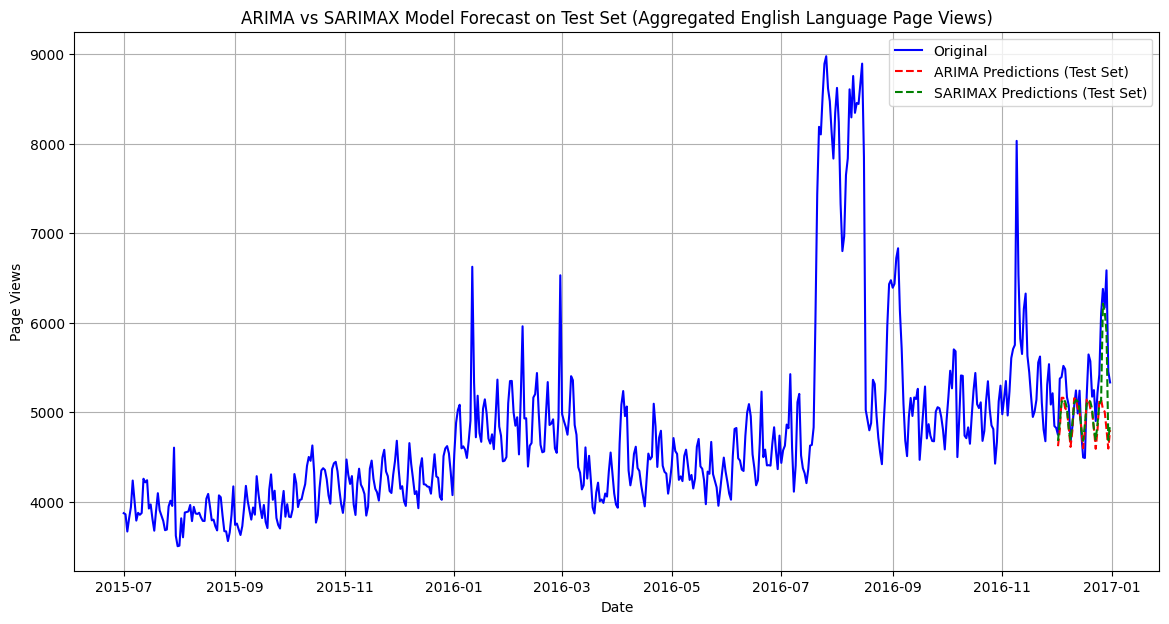

MAPE for SARIMAX model on the test set: 0.0535


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
import numpy as np


test_size = 30
exog_train = exog[:-test_size]
exog_test = exog[-test_size:]


exog_train.index = train_data.index
exog_test.index = test_data.index


seasonal_order = (0, 0, 0, 7)

print(f"Building SARIMAX model with non-seasonal order {best_order} and seasonal order {seasonal_order}...")

model_sarimax = SARIMAX(train_data,
                        order=best_order,
                        seasonal_order=seasonal_order,
                        exog=exog_train)

print("Fitting SARIMAX model on training data...")
model_sarimax_fit = model_sarimax.fit()

# Specify the start and end dates for prediction, and provide the exogenous variable for the test period
predictions_sarimax = model_sarimax_fit.predict(start=test_data.index[0],
                                               end=test_data.index[-1],
                                               exog=exog_test)


plt.figure(figsize=(14, 7))
plt.plot(train_en.index, train_en, label='Original', color='blue') # Original series in blue
# Check if predictions_arima_aligned exists before plotting
if 'predictions_arima_aligned' in locals():
    plt.plot(test_data.index, predictions_arima_aligned, label='ARIMA Predictions (Test Set)', color='red', linestyle='--')
plt.plot(test_data.index, predictions_sarimax, label='SARIMAX Predictions (Test Set)', color='green', linestyle='--')
plt.title('ARIMA vs SARIMAX Model Forecast on Test Set (Aggregated English Language Page Views)')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.grid(True)
plt.show()

# Get the actual values from the test set
actual_values = test_data

# Ensure actual_values and predictions_sarimax are aligned by index
actual_values_aligned_sarimax, predictions_sarimax_aligned = actual_values.align(predictions_sarimax, join='inner')

# Handle zero values in actual_values for MAPE calculation
epsilon = 1e-8 # A small number to avoid division by zero
actual_values_for_mape_sarimax = actual_values_aligned_sarimax.replace(0, epsilon)

# Calculate MAPE for the SARIMAX model on the test set
mape_sarimax_test = mean_absolute_percentage_error(actual_values_for_mape_sarimax, predictions_sarimax_aligned)

print(f"MAPE for SARIMAX model on the test set: {mape_sarimax_test:.4f}")

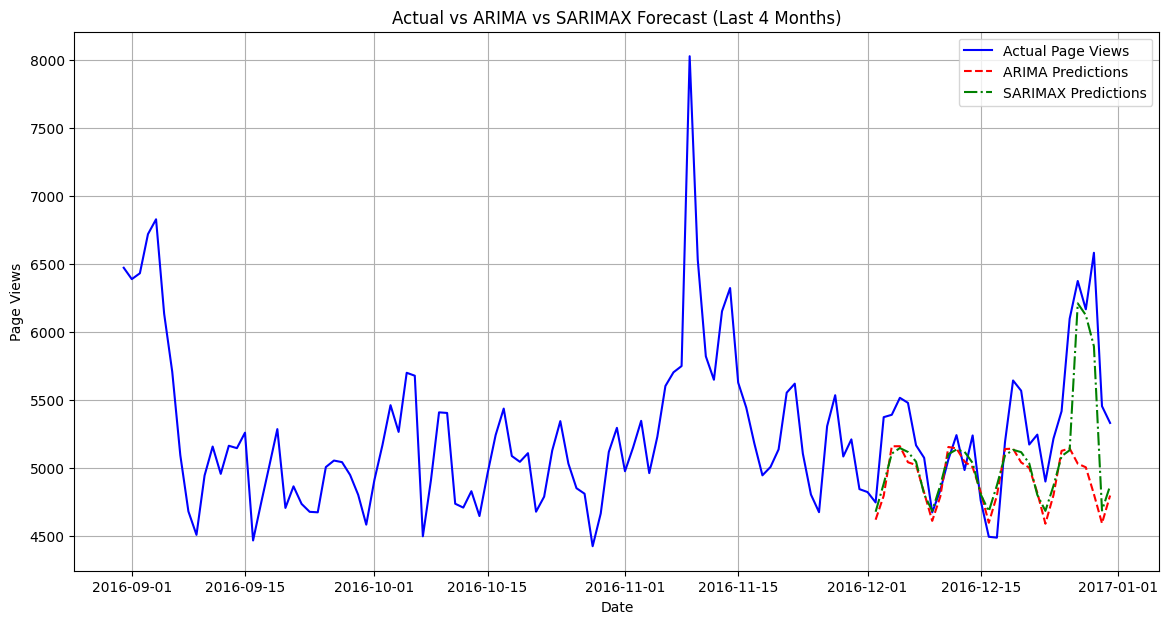

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Define the number of months to plot from the end of the time series
months_to_plot = 4
# Calculate the start date for the last 4 months
end_date = train_en.index[-1]
start_date = end_date - pd.DateOffset(months=months_to_plot)

# Slice the original time series data for the last 4 months
actual_last_months = train_en.loc[start_date:end_date]

# Slice the ARIMA predictions for the last 4 months
if 'predictions_arima_aligned' in locals():
    arima_predictions_last_months = predictions_arima_aligned.loc[start_date:end_date]
else:
    print("ARIMA predictions not found. Please run the ARIMA grid search cell (IfnpuEcRRhGl) first.")
    arima_predictions_last_months = None

# Slice the SARIMAX predictions for the last 4 months
if 'predictions_sarimax_aligned' in locals():
    sarimax_predictions_last_months = predictions_sarimax_aligned.loc[start_date:end_date]
else:
    print("SARIMAX predictions not found. Please run the SARIMAX evaluation cell (GNNViJGrJc95) first.")
    sarimax_predictions_last_months = None

# Plot the data for the last 4 months
plt.figure(figsize=(14, 7))
plt.plot(actual_last_months.index, actual_last_months, label='Actual Page Views', color='blue')

if arima_predictions_last_months is not None:
    plt.plot(arima_predictions_last_months.index, arima_predictions_last_months, label='ARIMA Predictions', color='red', linestyle='--')

if sarimax_predictions_last_months is not None:
    plt.plot(sarimax_predictions_last_months.index, sarimax_predictions_last_months, label='SARIMAX Predictions', color='green', linestyle='-.')


plt.title(f'Actual vs ARIMA vs SARIMAX Forecast (Last {months_to_plot} Months)')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def forecast_with_prophet(train_data, exog, test_size=30):

    prophet_train_df = train_data.reset_index()
    prophet_train_df.columns = ['ds', 'y']

    # Create a dataframe with the full date range for both training and testing/forecasting
    full_date_range = pd.date_range(start=train_data.index.min(), periods=len(train_data) + test_size, freq='D')
    full_date_df = pd.DataFrame({'ds': full_date_range})

    exog_with_datetime_index = exog.copy()
    exog_with_datetime_index.index = pd.date_range(start=train_data.index.min(), periods=len(exog), freq='D')

    exog_aligned_full = exog_with_datetime_index.reindex(full_date_range, fill_value=0).reset_index()
    exog_aligned_full.rename(columns={'index': 'ds'}, inplace=True)


    # Merge the training data with the aligned exogenous variable for training
    prophet_train_df = pd.merge(prophet_train_df, exog_aligned_full, on='ds', how='left')

    # --- Debugging: Check for NaNs in the training dataframe before fitting Prophet ---
    print("Checking for NaNs in prophet_train_df before fitting Prophet:")
    print(prophet_train_df.isnull().sum())
    # ----------------------------------------------------------------------------------


    # Initialize and fit the Prophet model
    # Add the exogenous variable as a regressor
    prophet_model = Prophet()
    prophet_model.add_regressor('Exog') # Add the exogenous variable as a regressor

    print("Fitting Prophet model on training data...")
    # --- Debugging: Check for NaNs in the dataframe passed to fit ---
    print("Checking for NaNs in the dataframe passed to prophet_model.fit:")
    print(prophet_train_df[['ds', 'y', 'Exog']].isnull().sum())
    # --------------------------------------------------------------
    prophet_model.fit(prophet_train_df)

    # Create future dataframe for forecasting
    future = prophet_model.make_future_dataframe(periods=test_size)

    # Merge the future dataframe with the full exogenous variable dataframe
    future = pd.merge(future, exog_aligned_full, on='ds', how='left')

    # --- Debugging: Check for NaNs in the future dataframe before predicting ---
    print("Checking for NaNs in future dataframe before predicting:")
    print(future.isnull().sum())
    # --- Debugging: Check for NaNs in the dataframe passed to predict ---
    print("Checking for NaNs in the dataframe passed to prophet_model.predict:")
    print(future[['ds', 'Exog']].isnull().sum())
    # ------------------------------------------------------------------------


    # Make predictions
    print("Making predictions with Prophet model...")
    prophet_forecast = prophet_model.predict(future)

    # Extract the predictions for the test period and set 'ds' as index
    test_start_date = train_data.index[-test_size]
    test_end_date = train_data.index[-1]

    # Slice the predicted values for the test period using the date range and set 'ds' as index
    prophet_predictions_test_df = prophet_forecast[(prophet_forecast['ds'] >= test_start_date) & (prophet_forecast['ds'] <= test_end_date)].copy()
    prophet_predictions_test = prophet_predictions_test_df.set_index('ds')['yhat']


    # Get the actual values for the test period
    actual_values_test = train_data.tail(test_size)

    # Ensure actual_values_test and prophet_predictions_test are aligned by index
    actual_values_test_aligned, prophet_predictions_test_aligned = actual_values_test.align(prophet_predictions_test, join='inner')

    # --- Debugging: Check the size of the aligned dataframes ---
    print(f"Size of actual_values_test_aligned: {len(actual_values_test_aligned)}")
    print(f"Size of prophet_predictions_test_aligned: {len(prophet_predictions_test_aligned)}")
    # -----------------------------------------------------------


    # Handle zero values in actual_values for MAPE calculation
    epsilon = 1e-8 # A small number to avoid division by zero
    actual_values_for_mape_prophet = actual_values_test_aligned.replace(0, epsilon)

    # Calculate MAPE only if there are data points after alignment
    if len(actual_values_test_aligned) > 0:
        mape_prophet = mean_absolute_percentage_error(actual_values_for_mape_prophet, prophet_predictions_test_aligned)
    else:
        mape_prophet = float('inf') # Set MAPE to infinity if no data to compare


    # Plot the forecast
    fig1 = prophet_model.plot(prophet_forecast)
    plt.title('Prophet Forecast with Exogenous Variable')
    plt.xlabel('Date')
    plt.ylabel('Page Views')
    plt.show()


    return mape_prophet, prophet_model, prophet_forecast

Checking for NaNs in prophet_train_df before fitting Prophet:
ds      0
y       0
Exog    0
dtype: int64


INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpyo0ybryo/17mlymo3.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpyo0ybryo/47hi89r_.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=65142', 'data', 'file=/tmp/tmpyo0ybryo/17mlymo3.json', 'init=/tmp/tmpyo0ybryo/47hi89r_.json', 'output', 'file=/tmp/tmpyo0ybryo/prophet_modelpr02pewg/prophet_model-20251012033047.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
03:30:47 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
03:30:48 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Fitting Prophet model on training data...
Checking for NaNs in the dataframe passed to prophet_model.fit:
ds      0
y       0
Exog    0
dtype: int64
Checking for NaNs in future dataframe before predicting:
ds      0
Exog    0
dtype: int64
Checking for NaNs in the dataframe passed to prophet_model.predict:
ds      0
Exog    0
dtype: int64
Making predictions with Prophet model...
Size of actual_values_test_aligned: 30
Size of prophet_predictions_test_aligned: 30


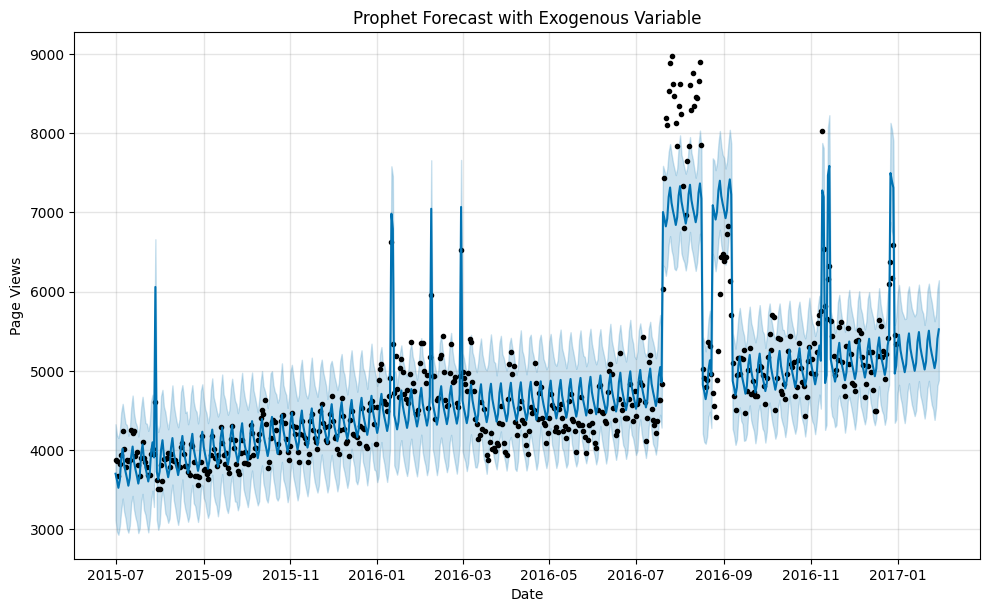

Prophet Model MAPE on Test Set: 0.0566


In [ ]:
test_size = 30

train_new = train.groupby('language').mean(numeric_only=True).transpose()
train_new.reset_index(inplace=True)
train_new['index'] = pd.to_datetime(train_new['index'])
train_new.set_index('index', inplace=True)
train_en = train_new['en']

# Call the forecast_with_prophet function
mape_prophet, prophet_model, prophet_forecast = forecast_with_prophet(train_en, exog, test_size=30)

# Print the calculated MAPE
print(f"Prophet Model MAPE on Test Set: {mape_prophet:.4f}")

**SARIMAX and Prophet:**

1) We now use SARIMAX model for forecasting and consider (6,1,6) as the best combination for order and (0,0,0,7) as a random starting point for seasonal_order. Ideally we need to try all possible combinations for (P,D,Q,s) but we will do that later in the code.
2) Basically we are focusing on the effect of the exogenous variable and using the non-seasonal ARIMA components (order=(p, d, q)) which were already optimised. We take the seasonality into account by setting s=7, but not yet explicitly modeling seasonal AR, differencing, or MA effects with non-zero P, D, or Q values. Hence we keep seasonal_order as (0,0,0,7).
3) We also plot the forecasted value of SARIMAX along with ARIMA against the actual values and can see that SARIMAX is able to capture the seasonality compared to ARIMA. Also the MAPE for SARIMAX is 5.35% which is much better than ARIMA (6.3%).
4) Please note that we create one more plot for SARIMAX and ARIMA against the actual values only for the last 6 months so that we can get a zoomed in view of the graph and can distinguish the plots accordingly (these plots were not easily distinguishable in the previously generated plots)
5) We now use prophet for forecasting and convert the data into only two columns: datetime and page_visits. We then fit the model and predict the values and also plot the forecasted values on a plot. We can see that the prohpet model has made a decent forecasting with a MAPE of 5.66% which is better than ARIMA but not better than SARIMAX.

In [ ]:
import pandas as pd
import numpy as np
import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_percentage_error
import warnings

warnings.filterwarnings("ignore") # Ignore warnings from SARIMAX fitting


test_size = 30
train_data = train_en[:-test_size]
test_data = train_en[-test_size:]

# Create a datetime index for the original exog based on the full date range length
full_date_range = pd.date_range(start=train_en.index.min(), periods=len(train_en), freq='D')
exog_with_datetime_index = exog.copy()
exog_with_datetime_index.index = full_date_range


# Split the exogenous variable into training and testing sets, aligning with the time series data
exog_train = exog_with_datetime_index[:-test_size]
exog_test = exog_with_datetime_index[-test_size:]


# Define the range for non-seasonal parameters (p, d, q)
p_range = range(0, 3) # Example: 0, 1, 2
d_range = range(0, 2) # Example: 0, 1
q_range = range(0, 3) # Example: 0, 1, 2

# Define the range for seasonal parameters (P, D, Q) and the seasonal period (s)
P_range = range(0, 2) # Example: 0, 1
D_range = range(0, 2) # Example: 0, 1
Q_range = range(0, 2) # Example: 0, 1
s = 7  # Seasonal period (weekly seasonality)

# Create a list of all possible combinations of (p, d, q)
pdq_combinations = list(itertools.product(p_range, d_range, q_range))

# Create a list of all possible combinations of (P, D, Q, s)
seasonal_pdq_combinations = [(x[0], x[1], x[2], s) for x in list(itertools.product(P_range, D_range, Q_range))]

# Initialize variables to store the best parameters and lowest MAPE
best_order = None
best_seasonal_order = None
lowest_mape_sarimax = float('inf') # Initialize with a very high value

print("Performing grid search for SARIMAX model...")

# Iterate through all combinations of non-seasonal and seasonal parameters
for order in pdq_combinations:
    for seasonal_order in seasonal_pdq_combinations:
        try:
            # Define the SARIMAX model
            # train_data is the endogenous variable (time series)
            # exog_train is the exogenous variable for the training period
            model_sarimax = SARIMAX(train_data,
                                    order=order,
                                    seasonal_order=seasonal_order,
                                    exog=exog_train)

            # Fit the model
            model_sarimax_fit = model_sarimax.fit(disp=False)

            # Make predictions on the test set
            # Specify the start and end dates for prediction, and provide the exogenous variable for the test period
            predictions_sarimax = model_sarimax_fit.predict(start=test_data.index[0],
                                                           end=test_data.index[-1],
                                                           exog=exog_test)

            # Ensure actual_values and predictions_sarimax are aligned by index
            actual_values_aligned_sarimax, predictions_sarimax_aligned = test_data.align(predictions_sarimax, join='inner')

            # Handle zero values in actual_values for MAPE calculation
            epsilon = 1e-8 # A small number to avoid division by zero
            actual_values_for_mape_sarimax = actual_values_aligned_sarimax.replace(0, epsilon)


            # Calculate MAPE
            # Ensure there are data points to calculate MAPE from after alignment
            if len(actual_values_for_mape_sarimax) > 0:
                 mape = mean_absolute_percentage_error(actual_values_for_mape_sarimax, predictions_sarimax_aligned)
            else:
                 mape = float('inf') # Set MAPE to infinity if no data to compare


            # Check if the current MAPE is lower than the lowest found so far
            if mape < lowest_mape_sarimax:
                lowest_mape_sarimax = mape
                best_order = order
                best_seasonal_order = seasonal_order

            print(f"SARIMAX{order}{seasonal_order} - MAPE: {mape:.4f}")

        except Exception as e:
            # Handle cases where a specific SARIMAX order fails to converge or fit
            # print(f"SARIMAX{order}{seasonal_order} - Error: {e}") # Optional: uncomment for detailed errors
            continue # Continue to the next combination if an error occurs

print("\nGrid search complete.")
print(f"Order with the lowest MAPE on the test set: {best_order}{best_seasonal_order}")
print(f"Lowest MAPE: {lowest_mape_sarimax:.4f}")

Performing grid search for SARIMAX model...
SARIMAX(0, 0, 0)(0, 0, 0, 7) - MAPE: 0.9121
SARIMAX(0, 0, 0)(0, 0, 1, 7) - MAPE: 0.8393
SARIMAX(0, 0, 0)(0, 1, 0, 7) - MAPE: 0.0602
SARIMAX(0, 0, 0)(0, 1, 1, 7) - MAPE: 0.0568
SARIMAX(0, 0, 0)(1, 0, 0, 7) - MAPE: 0.0639
SARIMAX(0, 0, 0)(1, 0, 1, 7) - MAPE: 0.0580
SARIMAX(0, 0, 0)(1, 1, 0, 7) - MAPE: 0.0537
SARIMAX(0, 0, 0)(1, 1, 1, 7) - MAPE: 0.0545
SARIMAX(0, 0, 1)(0, 0, 0, 7) - MAPE: 0.8930
SARIMAX(0, 0, 1)(0, 0, 1, 7) - MAPE: 0.8061
SARIMAX(0, 0, 1)(0, 1, 0, 7) - MAPE: 0.0582
SARIMAX(0, 0, 1)(0, 1, 1, 7) - MAPE: 0.0502
SARIMAX(0, 0, 1)(1, 0, 0, 7) - MAPE: 0.1022
SARIMAX(0, 0, 1)(1, 0, 1, 7) - MAPE: 0.2067
SARIMAX(0, 0, 1)(1, 1, 0, 7) - MAPE: 0.0528
SARIMAX(0, 0, 1)(1, 1, 1, 7) - MAPE: 0.0496
SARIMAX(0, 0, 2)(0, 0, 0, 7) - MAPE: 0.9384
SARIMAX(0, 0, 2)(0, 0, 1, 7) - MAPE: 0.7965
SARIMAX(0, 0, 2)(0, 1, 0, 7) - MAPE: 0.0584
SARIMAX(0, 0, 2)(0, 1, 1, 7) - MAPE: 0.0440
SARIMAX(0, 0, 2)(1, 0, 0, 7) - MAPE: 0.3654
SARIMAX(0, 0, 2)(1, 0, 1, 7) - M

**Grid search on SARIMAX:**
1. Out of the 3 models ie. ARIMA, SARIMAX and Prophet, SARIMAX gives the best performance in terms of MAPE. Hence we chose SARIMAX to perform grid search to find the optimal values for order and seasonal_order to further improve its performance.

**Order:**
1.   For 'p' (Non-seasonal AR order): A 'p' value of 0 means no past observations are directly used for forecasting (though past errors might be). A higher 'p' value means more past observations are considered. The range range(0,1,2) is a good starting point for non-seasonal AR orders, as often the most significant autocorrelation is found at the first few lags. Going too high can increase model complexity and risk overfitting.
2.   For 'd' (Non-seasonal differencing order): A 'd' value of 0 means the time series is assumed to be stationary. A 'd' value of 1 means the model uses the first difference of the series. A 'd' value of 2 means the model uses the difference of the first difference. In our earlier analysis, we saw that first-order differencing made the time series stationary so including d=1 is important. d=0 is also included in case differencing is not needed with other parameters or for comparison.
3.   For 'q' (Non-seasonal MA order): A 'q' value of 0 means the model does not use past forecast errors. A higher 'q' value means more past forecast errors are considered. Similar to 'p', the range range(0,1,2) is a good starting point for non-seasonal MA orders.


**Seasonal_order**:
1.   For 'P' (Seasonal AR order): This is the seasonal equivalent of 'p', representing the number of seasonal lag observations included in the model. The range range(0, 2) (0, 1) is a good starting point for seasonal parameters.
2.   For 'D' (Seasonal differencing order): This is the seasonal equivalent of 'd', representing the number of times the seasonal difference is applied. The range range(0, 1) is typically sufficient. Given the strong weekly seasonality (period s=7) observed in the data, a seasonal differencing order of D=1 is often necessary to remove this seasonality.
3.   For 'Q' (Seasonal MA order): This is the seasonal equivalent of 'q', representing the number of lagged seasonal forecast errors included in the model. The range range(0, 1) is a good starting point for seasonal parameters.
4.   For 's' (Seasonal period): This is the number of observations per seasonal cycle. Based on our earlier analysis and visual inspection of the time series plot and decomposition, we identified a strong weekly seasonality, so s is set to 7.
5.   We run the combinations and can see that the MAPE has reduced further to 4.23% with optimal values of (p,d,q) at (1,1,2) and (P,D,Q,s) at (1,0,1,7).
